<div style="padding: 20px 24px; border-radius: 12px; background: linear-gradient(110deg, #12304a, #187b8f); color: white; margin-bottom: 16px;">
  <div style="font-size: 0.78em; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.85;">HydroMT-SFINCS | Jakarta 05</div>
  <h1 style="color: white; margin: 8px 0 4px;">Peta genangan maksimum di area rencana</h1>
  <div style="opacity: 0.95;">Downscale muka air maksimum (zsmax) ke DEM resolusi tinggi, dipotong ke domain awal pesisir Jakarta.</div>
</div>

Mengikuti contoh resmi [5a_plot_results_hmax](https://deltares.github.io/hydromt_sfincs/latest/_examples/5a_plot_results_hmax.html) (baca `zsmax`, lalu `downscale_floodmap`).

<div style="padding: 14px 18px; border-left: 4px solid #187b8f; background: #eaf6f8; border-radius: 6px; margin: 12px 1em 12px 0; color: #111111;">
<strong>[JAKARTA] Note</strong>
<p style="margin: 8px 0 0;">Domain model dibuat luas (sampai Kep. Seribu) hanya supaya angin ERA5 punya fetch untuk membangkitkan setup di teluk. Area yang dinilai tetap domain awal pesisir Jakarta (<code>data/domain/domain_awal.geojson</code>, sama dengan region model 00_dasar_quadtree), jadi peta genangan dipotong ke sana. Laut (poligon <code>laut_copdem</code>) tidak diwarnai sebagai genangan.</p>
</div>

Butuh `sfincs_map.nc` dari notebook 03.

In [1]:
import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"  # [JAKARTA]
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx

from hydromt_sfincs import SfincsModel
from hydromt_sfincs.workflows.downscaling import downscale_floodmap

MSL = 1.12  # [JAKARTA] m EGM2008

C:\Users\ASUS\miniconda3\envs\asemelehoy\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\ASUS\miniconda3\envs\asemelehoy\Lib\site-packages\pyogrio\core.py:38: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


### Langkah 1: baca hasil model

In [2]:
sfincs_root = "../model/jakarta_2026"  # [JAKARTA]
mod = SfincsModel(sfincs_root, data_libs=["../data/data_catalog.yml"], mode="r")  # [JAKARTA]
mod.output.read()
zsmax = mod.output.data["zsmax"]
print(zsmax)

<xarray.DataArray 'zsmax' (timemax: 1, nmesh2d_face: 120426)> Size: 482kB
array([[      nan,       nan, 1.5913367, ..., 1.721469 , 1.7214577,
        1.7214452]], shape=(1, 120426), dtype=float32)
Coordinates:
  * timemax       (timemax) datetime64[ns] 8B 2026-10-30T23:00:00.312500
  * nmesh2d_face  (nmesh2d_face) int64 963kB 0 1 2 3 ... 120423 120424 120425
Attributes:
    units:          m
    standard_name:  maximum of sea_surface_height_above_reference_level
    long_name:      Maximum water level


### Langkah 2: [JAKARTA] area rencana dan DEM resolusi tinggi

DEM disusun dengan prioritas yang sama seperti model: reklamasi 2026 dulu, lalu DeltaDTM + tanggul.

In [3]:
crs = 32748
area = gpd.read_file("../data/domain/domain_awal.geojson").to_crs(crs)
bbox = tuple(area.to_crs(4326).total_bounds)

dtm = mod.data_catalog.get_rasterdataset("dtm_jakarta_tanggul", bbox=bbox, buffer=5).raster.mask_nodata()
rek = mod.data_catalog.get_rasterdataset("batimetri_reklamasi_2026", bbox=bbox, buffer=5).raster.mask_nodata()
rek = rek.raster.reproject_like(dtm, method="bilinear")
dep = rek.where(~np.isnan(rek), dtm)
dep = dep.raster.reproject(dst_crs=crs, dst_res=25, method="bilinear").raster.clip_geom(area, mask=True)  # 25 m = sel terkecil
dep.raster.set_nodata(np.nan)

laut = mod.data_catalog.get_geodataframe("laut_copdem", bbox=bbox).to_crs(crs)
darat = gpd.GeoDataFrame(geometry=[area.union_all().difference(laut.union_all())], crs=crs)
print(dep.shape, dep.raster.res)

(646, 1110) (np.float64(25.0), np.float64(-25.0))


### Langkah 3: downscale zsmax ke DEM

Kedalaman < 5 cm dianggap kering (`hmin` bawaan).

In [4]:
hmax = downscale_floodmap(
    zsmax=zsmax,
    dep=dep,
    reproj_method="nearest",
    hmin=0.05,
    gdf_mask=darat,  # [JAKARTA] hanya darat di area rencana
    floodmap_fn="../hasil/hmax_area_rencana.tif",
)
luas = float(np.isfinite(hmax).sum()) * abs(np.prod(hmax.raster.res)) / 1e6
print(f"luas tergenang (h > 5 cm): {luas:.2f} km2")

luas tergenang (h > 5 cm): 54.48 km2


### Langkah 4: [JAKARTA] peta di atas citra satelit

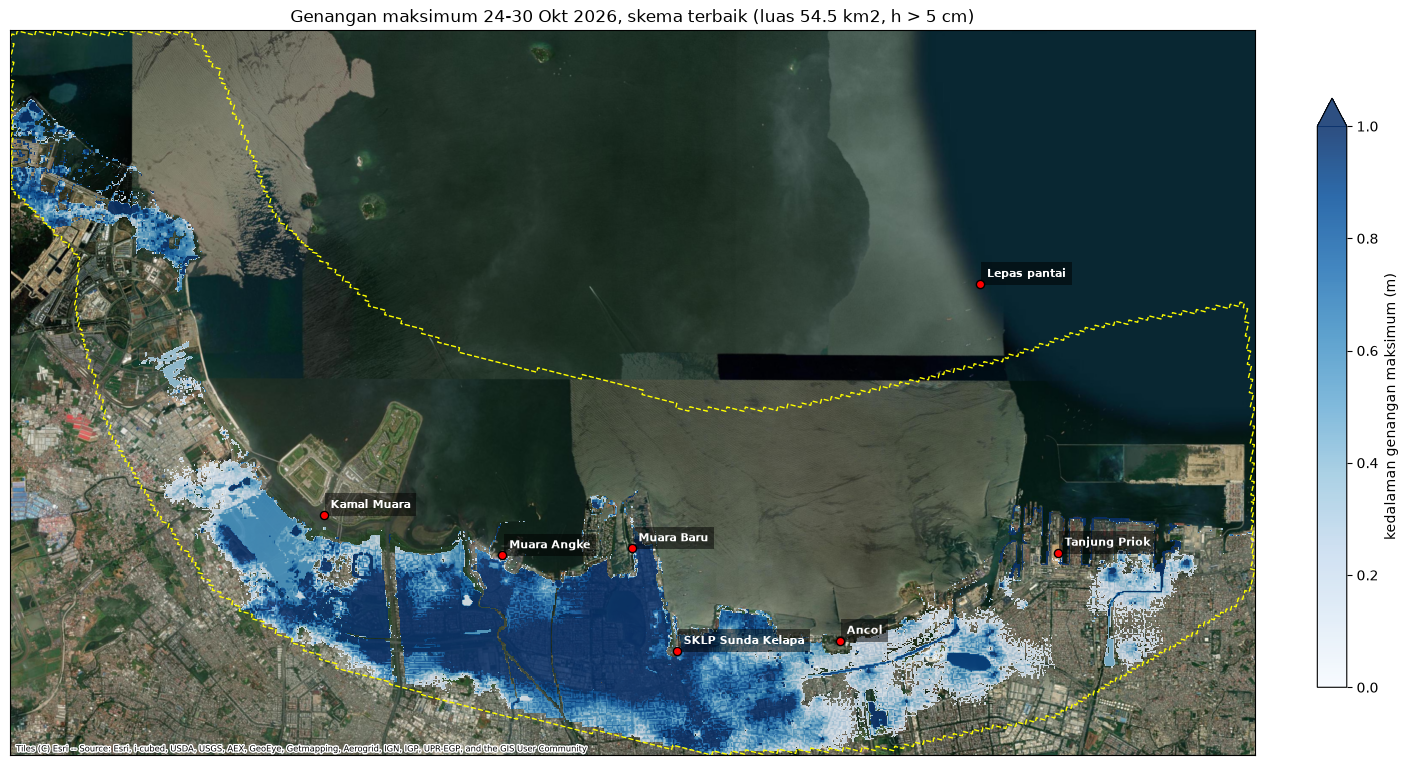

In [5]:
obs = gpd.read_file("../data/domain/titik_obs.geojson").to_crs(crs)
xmin, ymin, xmax, ymax = area.total_bounds

fig, ax = plt.subplots(figsize=(14, 8.5), constrained_layout=True)
ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
cx.add_basemap(ax, crs=f"EPSG:{crs}", source=cx.providers.Esri.WorldImagery, zoom=14, attribution_size=6)
im = hmax.plot(ax=ax, cmap="Blues", vmin=0, vmax=1.0, add_colorbar=False, alpha=0.85)
area.boundary.plot(ax=ax, color="yellow", lw=1, ls="--")
obs = obs.cx[xmin:xmax, ymin:ymax]
obs.plot(ax=ax, color="red", edgecolor="k", markersize=35, zorder=5)
for _, r in obs.iterrows():
    ax.annotate(r["name"].replace("_", " "), (r.geometry.x, r.geometry.y), xytext=(5, 5), textcoords="offset points",
                color="white", fontsize=8, fontweight="bold", bbox=dict(fc="black", alpha=0.5, lw=0))
fig.colorbar(im, ax=ax, shrink=0.7, extend="max", label="kedalaman genangan maksimum (m)")
ax.set_title(f"Genangan maksimum 24-30 Okt 2026, skema terbaik (luas {luas:.1f} km2, h > 5 cm)")
ax.set_xlabel(""); ax.set_ylabel(""); ax.set_xticks([]); ax.set_yticks([])
fig.savefig("../hasil/peta_genangan_area_rencana.png", dpi=150)